(44, 128, 128, 2)


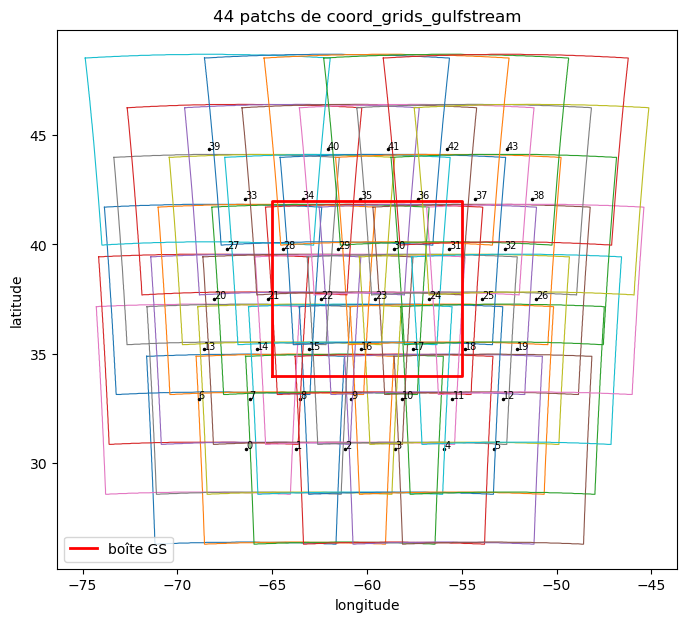

In [2]:
import numpy as np
import matplotlib.pyplot as plt

g = np.load("input_data/coord_grids_gulfstream.npy")
print(g.shape)

lon_min, lon_max = -65, -55
lat_min, lat_max = 34, 42

def contour(tab):
    # les 4 bords d'un tableau 128 x 128, dans l'ordre du tour
    haut = tab[0, :]
    droite = tab[:, -1]
    bas = tab[-1, ::-1]       # ::-1 = à l'envers, pour continuer le tour
    gauche = tab[::-1, 0]
    return np.concatenate([haut, droite, bas, gauche])

plt.figure(figsize=(8, 7))

for r in range(g.shape[0]):
    lon = (g[r, :, :, 0] + 180) % 360 - 180      # en [-180, 180], comme la boîte
    lat = g[r, :, :, 1]

    plt.plot(contour(lon), contour(lat), lw=0.8)
    plt.plot(lon[64, 64], lat[64, 64], 'k.', ms=3)              # centre du patch
    plt.text(lon[64, 64], lat[64, 64], str(r), fontsize=7)      # numéro du patch

# la boîte d'analyse
plt.plot([lon_min, lon_max, lon_max, lon_min, lon_min],
         [lat_min, lat_min, lat_max, lat_max, lat_min],
         'r', lw=2, label="boîte GS")

plt.xlabel("longitude")
plt.ylabel("latitude")
plt.legend()
plt.title(f"{g.shape[0]} patchs de coord_grids_gulfstream")
plt.savefig("patchs_gulfstream.png", dpi=150)
plt.show()
